Installing Required Libraries

In [ ]:
!pip install transformers datasets accelerate

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, DataCollatorForLanguageModeling


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Loading a small legal Dataset.

In [ ]:
from datasets import load_dataset

dataset = load_dataset("lex_glue", "ecthr_a", split="train[:1000]")
dataset = dataset.shuffle(seed=42).train_test_split(test_size=0.2)
print(dataset)


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/34.1k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/42.4M [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/5.68M [00:00<?, ?B/s]

validation-00000-of-00001.parquet:   0%|          | 0.00/5.26M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 800
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 200
    })
})


Loading Tokenizer and Model


In [ ]:
model_name = "distilgpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)
if tokenizer.pad_token is None:
    tokenizer.add_special_tokens({'pad_token': '[PAD]'})
    model.resize_token_embeddings(len(tokenizer))

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Prefunction Processing


In [ ]:
# Define preprocessing function based on the actual dataset structure
def preprocess_function(examples):
    # Handle the case where 'text' is a list of paragraphs
    if isinstance(examples["text"][0], list):
        # Join paragraphs into a single text for each example
        texts = [" ".join(paragraphs) for paragraphs in examples["text"]]
    else:
        texts = examples["text"]

    # Tokenize the texts
    model_inputs = tokenizer(
        texts,
        truncation=True,
        padding="max_length",
        max_length=512  # Increased from 256 to accommodate larger texts
    )

    # For causal LM, labels are the same as input_ids (not the dataset's 'labels')
    model_inputs["labels"] = model_inputs["input_ids"].copy()

    # Remove the dataset's original labels to avoid conflict
    if "labels" in examples:
        model_inputs.pop("labels", None)

    return model_inputs

Tokenize data

In [ ]:
text_only_dataset = dataset.remove_columns("labels")

# Apply tokenization to the dataset
tokenized_dataset = text_only_dataset.map(preprocess_function, batched=True)

# Create data collator for language modeling
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False  # We're not using masked language modeling for GPT models
)

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Create Trainer

In [ ]:
training_args = TrainingArguments(
    output_dir="./distilgpt2-legal",
    evaluation_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=50,
    save_total_limit=2,
    fp16=True,
    report_to="none"
)

# Create trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    tokenizer=tokenizer,
    data_collator=data_collator
)

<ipython-input-24-32137c612cf5>:18: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Train the Model

In [ ]:
trainer.train()

`loss_type=None` was set in the config but it is unrecognised.Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,2.527700,2.421220
2,2.289800,2.347539


Epoch,Training Loss,Validation Loss
1,2.527700,2.421220
2,2.289800,2.347539
3,2.276000,2.329853


TrainOutput(global_step=600, training_loss=2.480428975423177, metrics={'train_runtime': 13302.6782, 'train_samples_per_second': 0.18, 'train_steps_per_second': 0.045, 'total_flos': 313556100710400.0, 'train_loss': 2.480428975423177, 'epoch': 3.0})

Saving the model


In [ ]:
model.save_pretrained("./distilgpt2-legal-clean")
tokenizer.save_pretrained("./distilgpt2-legal-clean")
print("Model and tokenizer saved to ./distilgpt2-legal-clean")

Model and tokenizer saved to ./distilgpt2-legal-clean


Libraries for Evaluation

In [ ]:
!pip install datasets transformers torch scikit-learn pandas matplotlib seaborn tqdm

# Import required libraries
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from tqdm.auto import tqdm


Evaluation

Loading model from ./distilgpt2-legal-clean...
Model loaded successfully
Loading test dataset...
Loaded 100 test examples
Evaluating model...


  0%|          | 0/50 [00:00<?, ?it/s]

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end gene


Model Accuracy: 32.00%

Per-class Metrics:
Class 0: Precision=0.00, Recall=0.00, F1=0.00
Class 1: Precision=0.00, Recall=0.00, F1=0.00
Class 2: Precision=0.00, Recall=0.00, F1=0.00
Class 3: Precision=0.35, Recall=0.89, F1=0.50
Class 4: Precision=0.00, Recall=0.00, F1=0.00
Class 5: Precision=0.00, Recall=0.00, F1=0.00
Class 6: Precision=0.00, Recall=0.00, F1=0.00
Class 7: Precision=0.00, Recall=0.00, F1=0.00
Class 8: Precision=0.00, Recall=0.00, F1=0.00
Class 9: Precision=0.00, Recall=0.00, F1=0.00


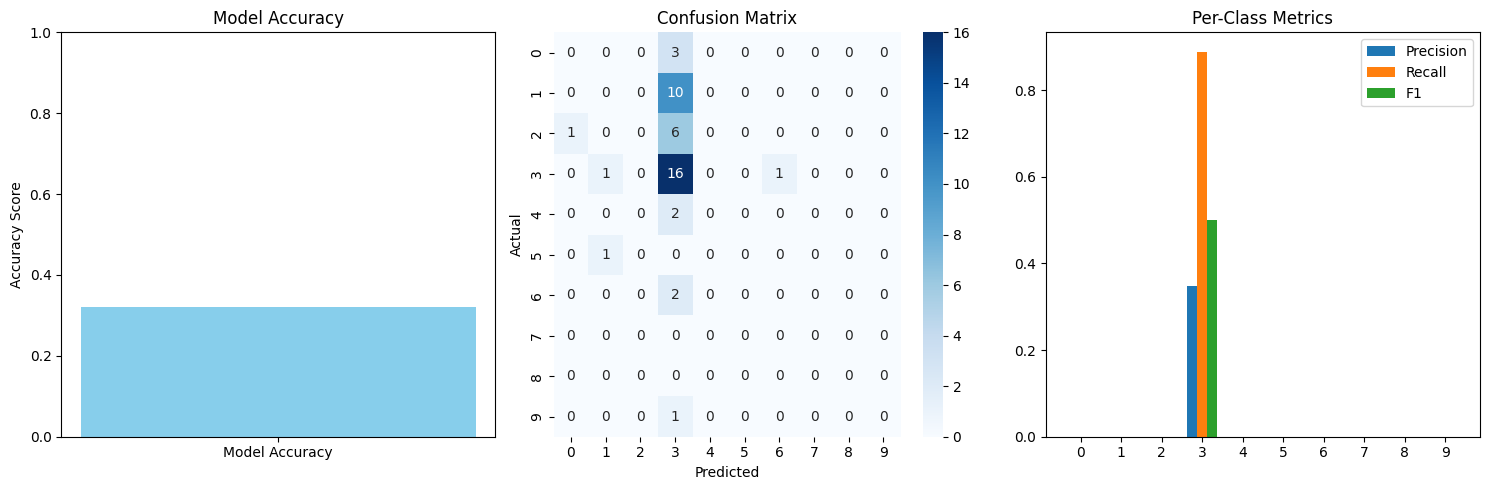


Evaluation complete. Results saved to CSV and plots saved as PNG.


In [ ]:
# Libraries for Evaluation
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from tqdm.auto import tqdm

# Load the saved model and tokenizer
model_path = "./distilgpt2-legal-clean"
print(f"Loading model from {model_path}...")
try:
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForCausalLM.from_pretrained(model_path)
    print("Model loaded successfully")
except Exception as e:
    print(f"Error loading model: {e}")
    print("Falling back to base model")
    tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
    model = AutoModelForCausalLM.from_pretrained("distilgpt2")

# Load test dataset
print("Loading test dataset...")
test_dataset = load_dataset("lex_glue", "ecthr_a", split="test[:100]")
print(f"Loaded {len(test_dataset)} test examples")

# Preprocessing function
def preprocess_text(example):
    if isinstance(example["text"], list):
        return " ".join(example["text"])
    return example["text"]

# Prediction generation - FIXED VERSION
def generate_prediction(text, model, tokenizer, max_new_tokens=50):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        outputs = model.generate(
            input_ids=inputs.input_ids,
            attention_mask=inputs.attention_mask,
            max_new_tokens=max_new_tokens,  # Changed from max_length to max_new_tokens
            temperature=0.7,
            top_k=50,
            top_p=0.95,
            do_sample=True,
        )
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Label extraction
article_mapping = {
    "article 2": 0, "article 3": 1, "article 5": 2, "article 6": 3,
    "article 8": 4, "article 9": 5, "article 10": 6, "article 11": 7,
    "article 14": 8, "protocol 1": 9
}

def extract_prediction(generated_text):
    predictions = []
    generated_text = generated_text.lower()
    for article, label in article_mapping.items():
        if article in generated_text:
            predictions.append(label)
    return predictions if predictions else [3]  # Default to most common class

# Evaluation function
def evaluate_model(test_data, model, tokenizer, num_samples=50):
    results = []
    true_labels = []
    pred_labels = []

    for sample in tqdm(test_data.select(range(num_samples))):
        text = preprocess_text(sample)
        true_label = sample["labels"][0] if sample["labels"] else -1

        try:
            generated_text = generate_prediction(text, model, tokenizer)
            pred_label = extract_prediction(generated_text)[0]

            true_labels.append(true_label)
            pred_labels.append(pred_label)

            results.append({
                "text": text[:100] + "...",  # Store first 100 chars for reference
                "true_label": true_label,
                "pred_label": pred_label,
                "correct": true_label == pred_label
            })
        except Exception as e:
            print(f"Error processing sample: {e}")
            continue

    if not true_labels:  # Handle case where all samples failed
        print("Warning: No valid predictions were generated")
        return pd.DataFrame(), {
            "accuracy": 0,
            "confusion_matrix": np.zeros((10, 10)),
            "precision": np.zeros(10),
            "recall": np.zeros(10),
            "f1": np.zeros(10)
        }

    accuracy = accuracy_score(true_labels, pred_labels)
    conf_matrix = confusion_matrix(true_labels, pred_labels, labels=range(10))
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, pred_labels, average=None, labels=range(10), zero_division=0
    )

    return pd.DataFrame(results), {
        "accuracy": accuracy,
        "confusion_matrix": conf_matrix,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# Run evaluation
print("Evaluating model...")
eval_results, metrics = evaluate_model(test_dataset, model, tokenizer)

# Print metrics
print(f"\nModel Accuracy: {metrics['accuracy']:.2%}")
print("\nPer-class Metrics:")
for i in range(10):
    print(f"Class {i}: Precision={metrics['precision'][i]:.2f}, Recall={metrics['recall'][i]:.2f}, F1={metrics['f1'][i]:.2f}")

# Visualization
plt.figure(figsize=(15, 5))

# Accuracy plot
plt.subplot(1, 3, 1)
plt.bar(['Model Accuracy'], [metrics['accuracy']], color='skyblue')
plt.ylim(0, 1)
plt.title('Model Accuracy')
plt.ylabel('Accuracy Score')

# Confusion matrix
plt.subplot(1, 3, 2)
sns.heatmap(metrics['confusion_matrix'], annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Precision-Recall-F1
plt.subplot(1, 3, 3)
x = np.arange(10)
width = 0.25
plt.bar(x - width, metrics['precision'], width, label='Precision')
plt.bar(x, metrics['recall'], width, label='Recall')
plt.bar(x + width, metrics['f1'], width, label='F1')
plt.xticks(x, range(10))
plt.legend()
plt.title('Per-Class Metrics')

plt.tight_layout()
plt.savefig('model_evaluation_results.png', dpi=300)
plt.show()

# Save results
eval_results.to_csv('model_evaluation_results.csv', index=False)
print("\nEvaluation complete. Results saved to CSV and plots saved as PNG.")